# Digit Recognition with sklearn (before I learned CNNs)

This was my first stab at handwritten digits using only sklearn — the 8x8 `load_digits` dataset, not the full MNIST. Comparing logistic regression to a small MLP. I'm keeping this notebook around because looking back at it makes the jump to a CNN feel motivated rather than arbitrary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(0)

(1797, 64)   classes: [0 1 2 3 4 5 6 7 8 9]


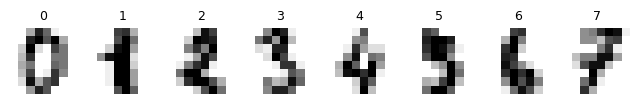

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print(X.shape, "  classes:", np.unique(y))

# show a few
fig, axes = plt.subplots(1, 8, figsize=(8, 1.5))
for ax, img, label in zip(axes, digits.images[:8], y[:8]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label, fontsize=9); ax.axis("off")
plt.show()

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

lr = Pipeline([("sc", StandardScaler()),
                ("clf", LogisticRegression(max_iter=2000))])
lr.fit(X_tr, y_tr)
print("LogReg accuracy:", lr.score(X_te, y_te))

# small MLP — single hidden layer, no fancy tuning
mlp = MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0)
mlp.fit(X_tr, y_tr)
print("MLP accuracy:   ", mlp.score(X_te, y_te))

LogReg accuracy: 0.9688888888888889


MLP accuracy:    0.9755555555555555


In [4]:
# print the harder-to-call digit pairs from the confusion matrix
cm = confusion_matrix(y_te, mlp.predict(X_te))
off_diag = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            off_diag.append((cm[i, j], i, j))
off_diag.sort(reverse=True)
print("top confusions (true -> pred, count):")
for n, i, j in off_diag[:6]:
    print(f"  {i} -> {j}: {n}")

top confusions (true -> pred, count):
  8 -> 1: 3
  8 -> 3: 2
  9 -> 5: 1
  9 -> 3: 1
  6 -> 1: 1
  5 -> 8: 1


## What I'd change now

The 8x8 digits dataset is so coarse that even logistic regression on flattened pixels does fine. The MLP edges it slightly but not by much. Treating the image as a flat 64-vector throws away the 2D structure — which is exactly the gap a CNN closes.

I left this notebook simple on purpose. The next one (53, written later) is the actual CNN on full 28x28 MNIST.